3115
351
359


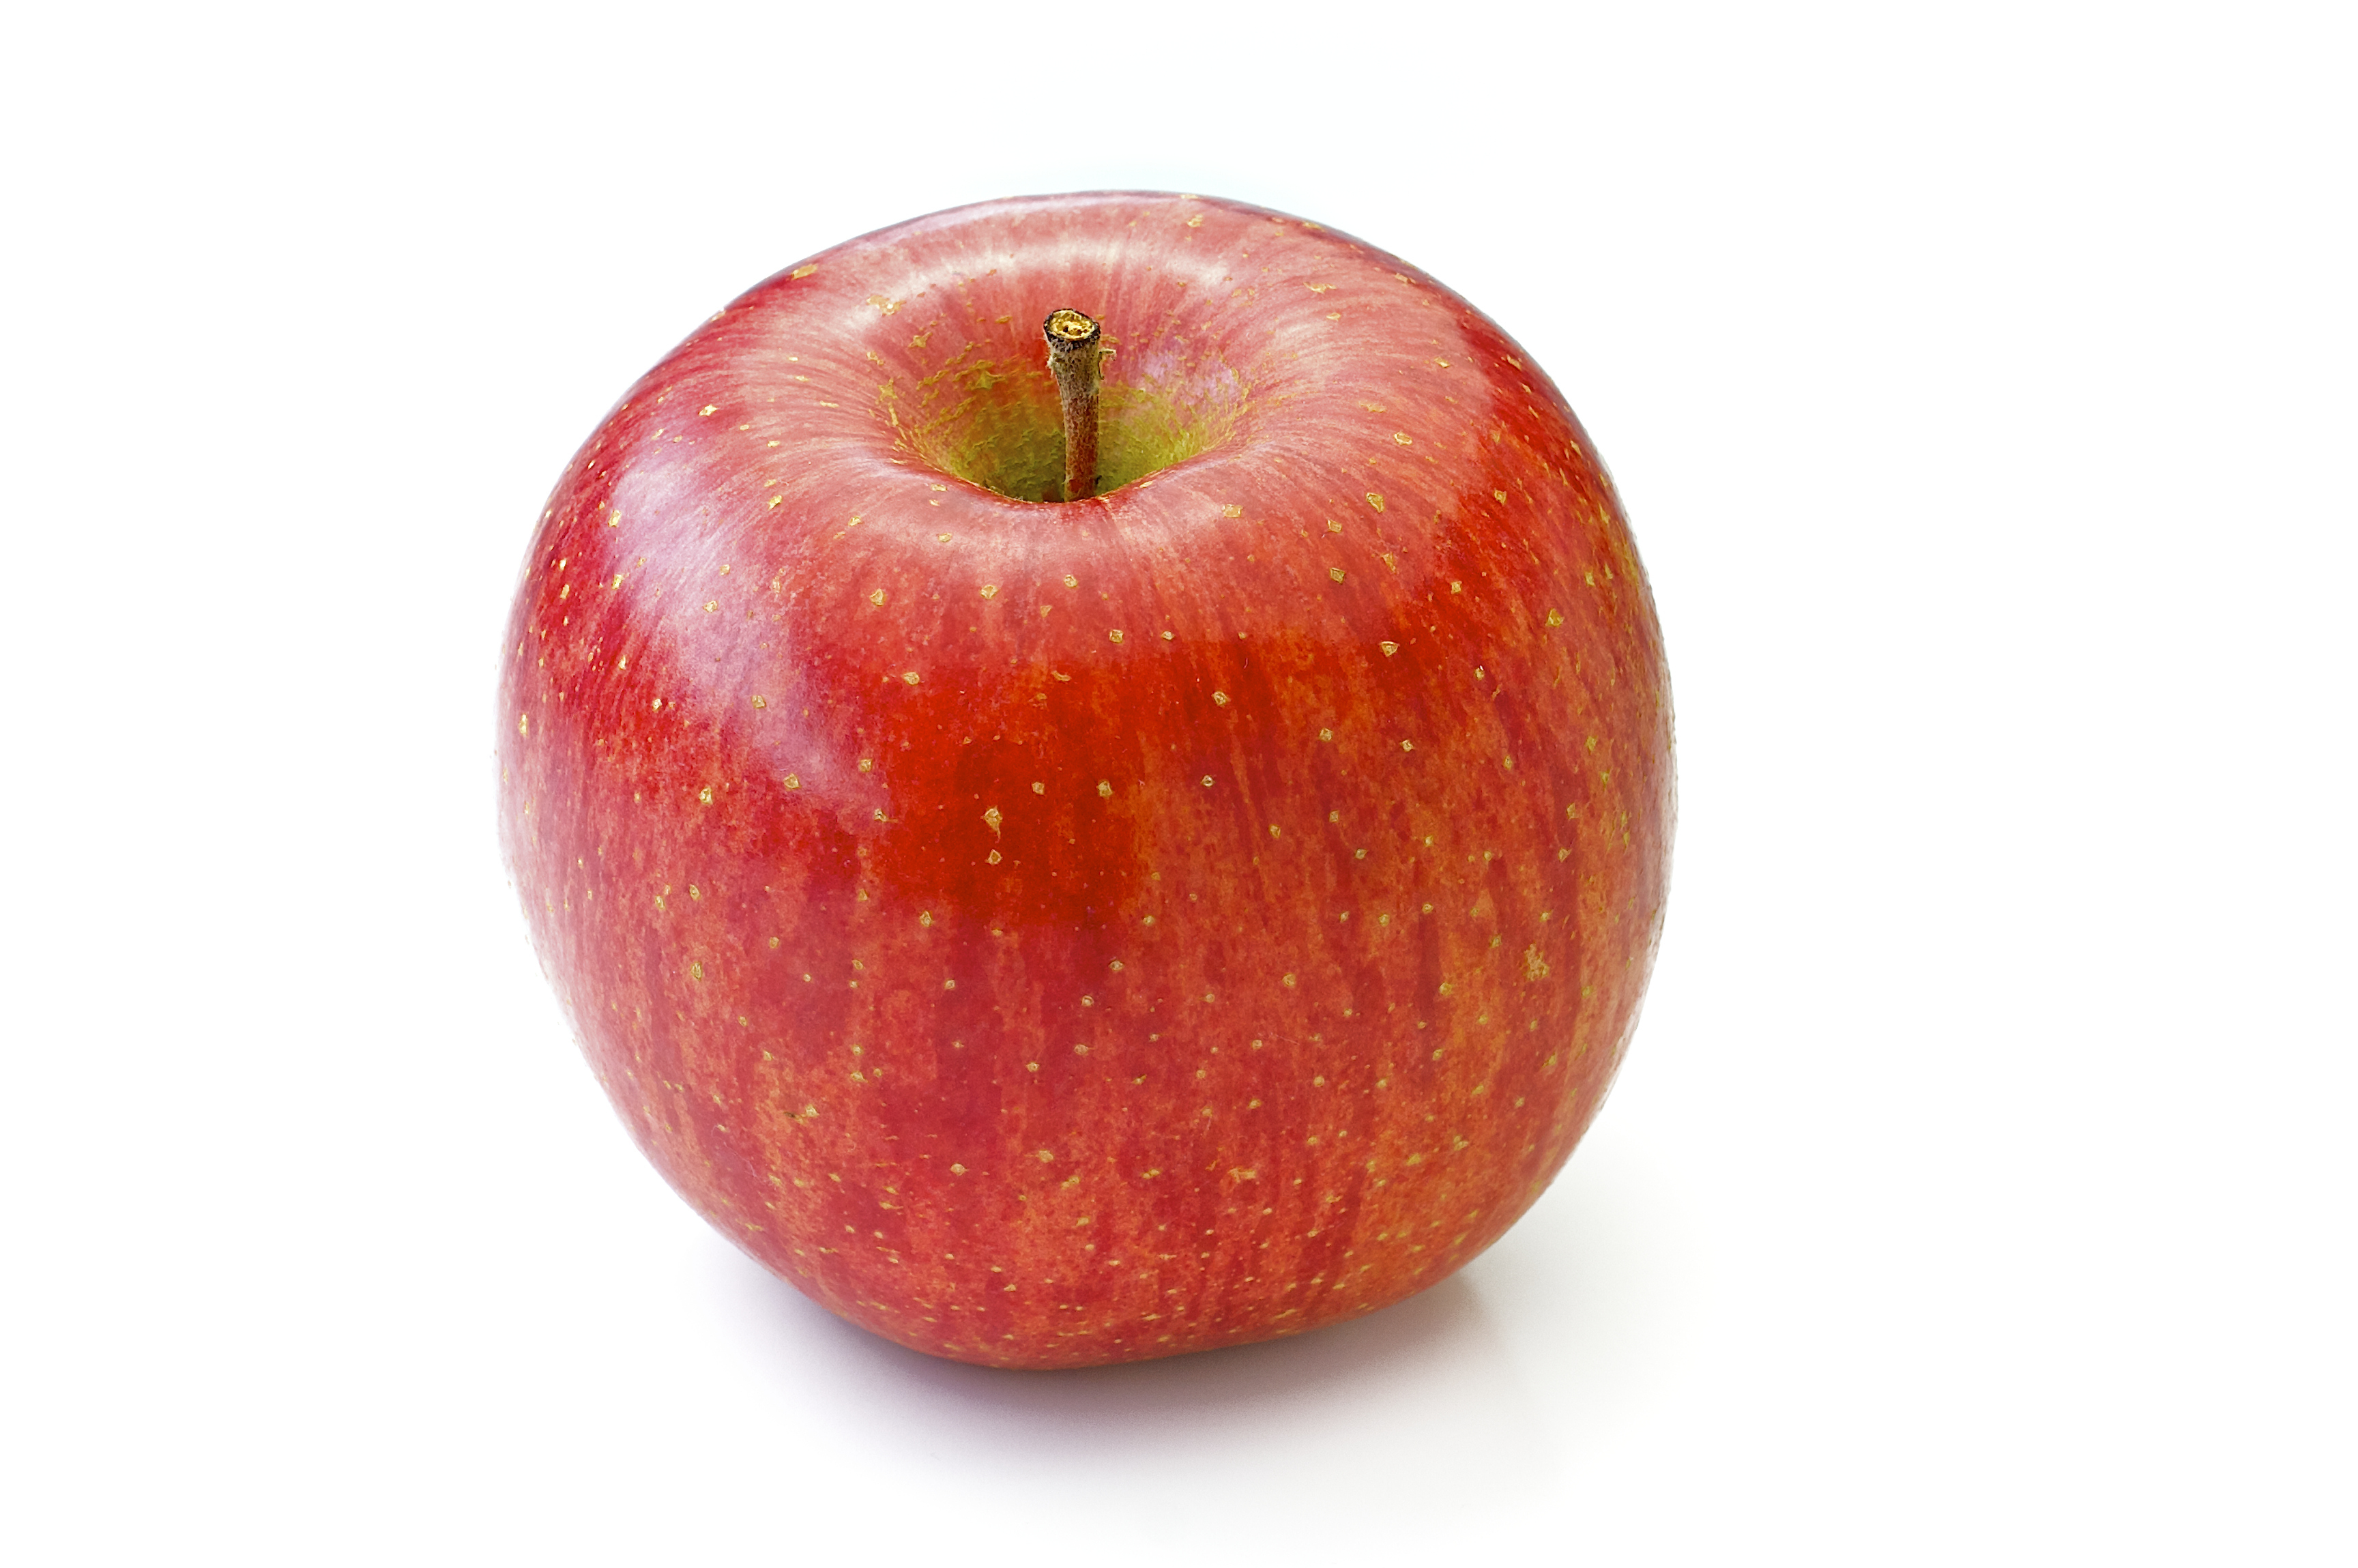

In [93]:
#dataset and code for produce classification - https://www.kaggle.com/code/databeru/fruit-and-vegetable-classification
#https://www.geeksforgeeks.org/python/pathlib-module-in-python/ - path also https://www.reddit.com/r/learnpython/comments/zf8qz7/help_understanding_relative_paths_in_python/
#https://www.tensorflow.org/tutorials/load_data/images - load from local

#https://stackoverflow.com/a/64448353 - cleanup of warnings
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'  # or any {'0', '1', '2'}
import tensorflow as tf


#https://coremltools.readme.io/v4.0/docs/introductory-quickstart

import tensorflow as tf
import numpy as np
import os
import PIL
import PIL.Image
import tensorflow_datasets as tfds
import pathlib

#Getting data loaded and verifying it is reachable
data_dir = pathlib.Path("/Users/frederikdahlhansen/Documents/nowastemate-backend/ML/dataset")
#https://www.reddit.com/r/learnpython/s/QFiByrJ3Vp
train_dir = data_dir / "train"
val_dir = data_dir / "validation"
test_dir = data_dir / "test"

train_count = len(list(train_dir.glob('*/*')))
val_count = len(list(val_dir.glob('*/*')))
test_count = len(list(test_dir.glob('*/*')))

print(train_count)
print(val_count)
print(test_count)

apple_test = list(train_dir.glob('apple/*'))
PIL.Image.open(str(apple_test[5]))



Found 3115 files belonging to 36 classes.
Found 351 files belonging to 36 classes.
Found 359 files belonging to 36 classes.


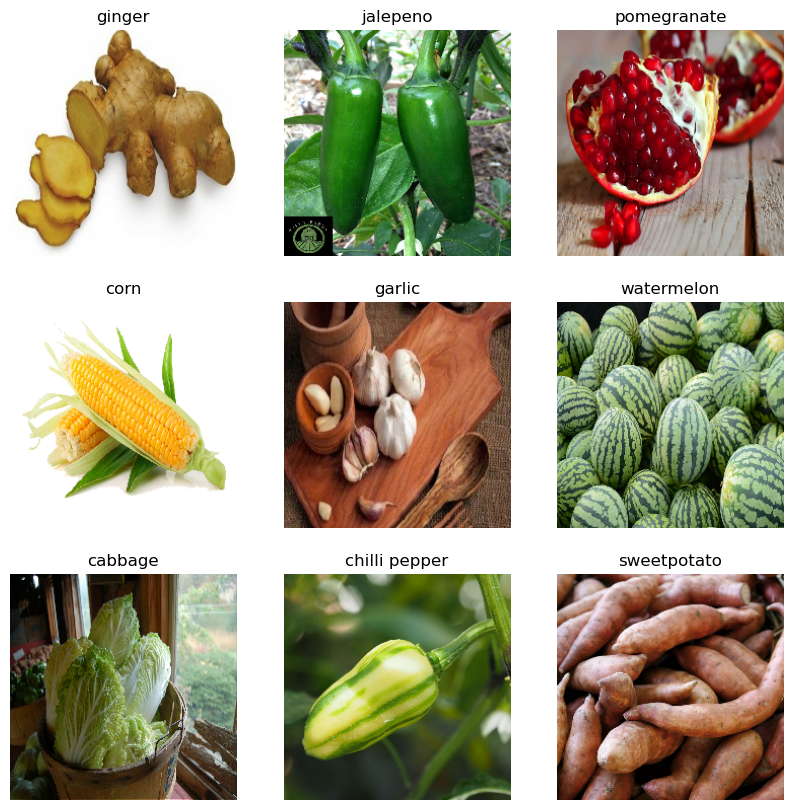

In [94]:
#https://www.tensorflow.org/api_docs/python/tf/keras/applications/MobileNetV2
#https://www.tensorflow.org/tutorials/images/transfer_learning
BATCH_SIZE = 32
#https://discuss.pytorch.org/t/size-of-input-images-tensor-to-mobilenet-and-other-pretrained-models/84359 
#Common size is 224. This is a more intensive process, but phone is powerful.
IMG_SIZE = (224, 224)

#https://blog.dailydoseofds.com/p/why-is-it-important-to-shuffle-your
train_dataset = tf.keras.utils.image_dataset_from_directory(train_dir,
                                                            shuffle=True,
                                                            batch_size=BATCH_SIZE,
                                                            image_size=IMG_SIZE)

validation_dataset = tf.keras.utils.image_dataset_from_directory(val_dir,
                                                                 shuffle=True,
                                                                 batch_size=BATCH_SIZE,
                                                                 image_size=IMG_SIZE)

test_dataset = tf.keras.utils.image_dataset_from_directory(test_dir,
                                                                 shuffle=False, #keep sorted to evaluate later
                                                                 batch_size=BATCH_SIZE,
                                                                 image_size=IMG_SIZE)



class_names = train_dataset.class_names

import matplotlib.pyplot as plt
plt.figure(figsize=(10, 10))
for images, labels in train_dataset.take(1):
  for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(class_names[labels[i]])
    plt.axis("off")



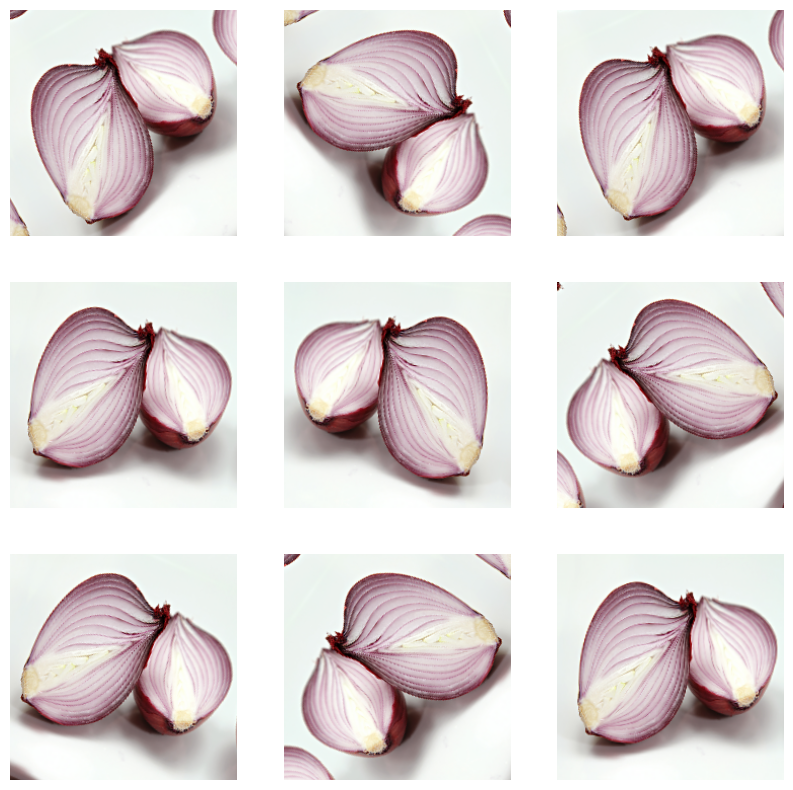

In [95]:
#adding variance to photos.
#This will help with real world pictures, where angle can differ

data_augmentation = tf.keras.Sequential([
  tf.keras.layers.RandomFlip('horizontal'),
  tf.keras.layers.RandomRotation(0.2),
])

for image, _ in train_dataset.take(1):
  plt.figure(figsize=(10, 10))
  first_image = image[0]
  for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    augmented_image = data_augmentation(tf.expand_dims(first_image, 0))
    plt.imshow(augmented_image[0] / 255)
    plt.axis('off')



In [96]:
#model expect -1 to 1 values, but they come as 0 to 255 currently, this fixes this - https://www.tensorflow.org/tutorials/images/transfer_learning#rescale_pixel_values
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input

#Create the base model from the pre-trained model MobileNet V2
IMG_SHAPE = IMG_SIZE + (3,)
base_model = tf.keras.applications.MobileNetV2(input_shape=IMG_SHAPE,
                                               include_top=False,
                                               weights='imagenet')

image_batch, label_batch = next(iter(train_dataset))
feature_batch = base_model(image_batch)
print(feature_batch.shape)


#freeze the base model to ensure new data does not interfere
base_model.trainable = False



(32, 7, 7, 1280)


In [97]:
#https://www.tensorflow.org/tutorials/images/transfer_learning#add_a_classification_head

global_average_layer = tf.keras.layers.GlobalAveragePooling2D()
feature_batch_average = global_average_layer(feature_batch)
print(feature_batch_average.shape)

#https://keras.io/api/layers/core_layers/dense/
#https://www.geeksforgeeks.org/deep-learning/the-role-of-softmax-in-neural-networks-detailed-explanation-and-applications/
prediction_layer = tf.keras.layers.Dense(len(train_dataset.class_names), activation='softmax')
prediction_batch = prediction_layer(feature_batch_average)
print(prediction_batch.shape)

(32, 1280)
(32, 36)


In [98]:
#putting model together 
#https://www.tensorflow.org/tutorials/images/transfer_learning#add_a_classification_head
inputs = tf.keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = preprocess_input(x)
x = base_model(x, training=False)
x = global_average_layer(x)
#https://www.youtube.com/watch?v=_vydpu_VXtA
x = tf.keras.layers.Dropout(0.2)(x)
outputs = prediction_layer(x)
model = tf.keras.Model(inputs, outputs)

In [99]:
model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_1 (Subtract)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 36)             │        46,116 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,304,100 (8.79 MB)

 Trainable params: 46,116 (180.14 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [101]:
#https://www.geeksforgeeks.org/machine-learning/impact-of-learning-rate-on-a-model/
#https://www.geeksforgeeks.org/deep-learning/adam-optimizer/
base_learning_rate = 0.001
#https://www.tensorflow.org/api_docs/python/tf/keras/losses/SparseCategoricalCrossentropy
#https://www.tensorflow.org/api_docs/python/tf/keras/losses/CategoricalCrossentropy
#https://www.tensorflow.org/tutorials/images/data_augmentation#train_a_model
#https://www.geeksforgeeks.org/machine-learning/what-is-label-smoothing/ - to investigate later

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=base_learning_rate),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)



In [102]:
#initial_epochs = 10 - Tried with 10, but there looked to be more to performance to extract still
initial_epochs = 15

loss0, accuracy0 = model.evaluate(validation_dataset)

print("initial loss: {:.2f}".format(loss0))
print("initial accuracy: {:.2f}".format(accuracy0))

history = model.fit(train_dataset,
                    epochs=initial_epochs,
                    validation_data=validation_dataset)

11/11 ━━━━━━━━━━━━━━━━━━━━ 16s 520ms/step - accuracy: 0.0256 - loss: 3.8972
initial loss: 3.90
initial accuracy: 0.03
Epoch 1/15
98/98 ━━━━━━━━━━━━━━━━━━━━ 21s 166ms/step - accuracy: 0.4764 - loss: 1.9666 - val_accuracy: 0.8120 - val_loss: 0.6978
Epoch 2/15
98/98 ━━━━━━━━━━━━━━━━━━━━ 15s 151ms/step - accuracy: 0.7554 - loss: 0.8495 - val_accuracy: 0.8718 - val_loss: 0.4657
Epoch 3/15
98/98 ━━━━━━━━━━━━━━━━━━━━ 13s 130ms/step - accuracy: 0.8109 - loss: 0.6414 - val_accuracy: 0.8832 - val_loss: 0.3776
Epoch 4/15
98/98 ━━━━━━━━━━━━━━━━━━━━ 16s 165ms/step - accuracy: 0.8369 - loss: 0.5444 - val_accuracy: 0.9060 - val_loss: 0.3354
Epoch 5/15
98/98 ━━━━━━━━━━━━━━━━━━━━ 14s 138ms/step - accuracy: 0.8472 - loss: 0.4778 - val_accuracy: 0.9088 - val_loss: 0.2946
Epoch 6/15
98/98 ━━━━━━━━━━━━━━━━━━━━ 14s 144ms/step - accuracy: 0.8690 - loss: 0.4345 - val_accuracy: 0.9231 - val_loss: 0.2726
Epoch 7/15
98/98 ━━━━━━━━━━━━━━━━━━━━ 13s 136ms/step - accuracy: 0.8864 - loss: 0.3827 - val_accuracy: 0.914

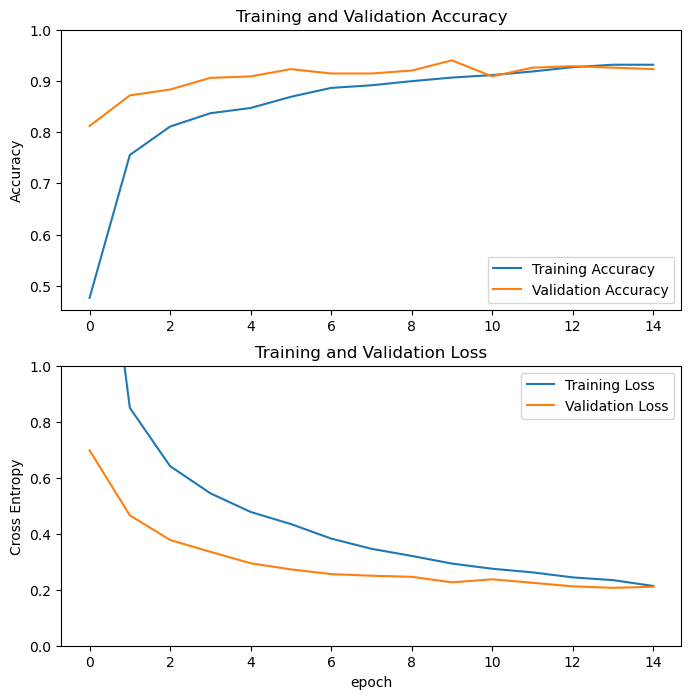

In [103]:
#https://www.tensorflow.org/tutorials/images/transfer_learning#learning_curves
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

plt.figure(figsize=(8, 8))
plt.subplot(2, 1, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.ylabel('Accuracy')
plt.ylim([min(plt.ylim()),1])
plt.title('Training and Validation Accuracy')

plt.subplot(2, 1, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.ylabel('Cross Entropy')
plt.ylim([0,1.0])
plt.title('Training and Validation Loss')
plt.xlabel('epoch')
plt.show()

In [104]:
#https://www.tensorflow.org/tutorials/images/transfer_learning#fine_tuning
base_model.trainable = True
print("Number of layers in the base model: ", len(base_model.layers))

#Fine-tune from this layer onwards
fine_tune_at = 100

#Freeze all the layers before the `fine_tune_at` layer
for layer in base_model.layers[:fine_tune_at]:
  layer.trainable = False

#recompile
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=base_learning_rate/10),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)
model.summary()

Number of layers in the base model:  154


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_1 (Subtract)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 36)             │        46,116 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,304,100 (8.79 MB)

 Trainable params: 1,907,556 (7.28 MB)

 Non-trainable params: 396,544 (1.51 MB)

In [105]:
#re-train
#https://www.tensorflow.org/tutorials/images/transfer_learning#fine_tuning
fine_tune_epochs = 10
total_epochs =  initial_epochs + fine_tune_epochs

history_fine = model.fit(train_dataset,
                         epochs=total_epochs,
                         initial_epoch=len(history.epoch),
                         validation_data=validation_dataset)

Epoch 16/25
98/98 ━━━━━━━━━━━━━━━━━━━━ 54s 436ms/step - accuracy: 0.8042 - loss: 0.6074 - val_accuracy: 0.9031 - val_loss: 0.2798
Epoch 17/25
98/98 ━━━━━━━━━━━━━━━━━━━━ 36s 361ms/step - accuracy: 0.8831 - loss: 0.3582 - val_accuracy: 0.8974 - val_loss: 0.2709
Epoch 18/25
98/98 ━━━━━━━━━━━━━━━━━━━━ 32s 320ms/step - accuracy: 0.9169 - loss: 0.2498 - val_accuracy: 0.9231 - val_loss: 0.2243
Epoch 19/25
98/98 ━━━━━━━━━━━━━━━━━━━━ 30s 299ms/step - accuracy: 0.9223 - loss: 0.2257 - val_accuracy: 0.9373 - val_loss: 0.2205
Epoch 20/25
98/98 ━━━━━━━━━━━━━━━━━━━━ 29s 291ms/step - accuracy: 0.9358 - loss: 0.1928 - val_accuracy: 0.9231 - val_loss: 0.2386
Epoch 21/25
98/98 ━━━━━━━━━━━━━━━━━━━━ 36s 360ms/step - accuracy: 0.9445 - loss: 0.1764 - val_accuracy: 0.9430 - val_loss: 0.1906
Epoch 22/25
98/98 ━━━━━━━━━━━━━━━━━━━━ 27s 271ms/step - accuracy: 0.9515 - loss: 0.1431 - val_accuracy: 0.9430 - val_loss: 0.1792
Epoch 23/25
98/98 ━━━━━━━━━━━━━━━━━━━━ 33s 331ms/step - accuracy: 0.9599 - loss: 0.1271 - 